# UN Comtrade: Bounded Extraction & Data Readiness

**Objective:** Build a reproducible, deliberately bounded extraction of Germany's annual merchandise trade by **partner and HS product chapter**. Inspect source coverage and quality before handing data to a relational model.

**Scope:** 2023–2024 · Germany (reporter `276`) · imports (`M`) and exports (`X`) · HS chapters **84, 85, 87** · partner filter omitted (returns available partners, including the World aggregate when reported).

**Execution:** **Offline by default.** All cells can be rerun without network access. Live requests require explicitly changing a `RUN_LIVE_*` flag; the client retains its cache, pacing, retry, and local quota safeguards. Saved raw snapshots are never manually edited.

**Requirements:** The repository's Python environment (`requirements.txt`), `src/config.py`, `src/extract.py`, and a UN Comtrade API key in `.env` **only if** live extraction is enabled. Cached data live under `data/raw/`, which may not be present in a fresh clone.

**Reference:** [UN Comtrade API](https://uncomtrade.org/docs/un-comtrade-api/) · [Query options](https://uncomtrade.org/docs/data/).

## 1. Environment & Setup

Load the repository's existing extraction client. A request is not sent when the client is constructed. The notebook discovers the project root whether Jupyter started from `notebooks/` or the repository root.

In [ ]:
from pathlib import Path
import hashlib
import json
import sys
from itertools import product
import matplotlib.pyplot as plt
import pandas as pd
# find the project root
working_dir = Path.cwd().resolve()
project_root = next(
    (p for p in (working_dir, *working_dir.parents) if (p / "src" / "extract.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Open this notebook from inside the global-trade-flow-pipeline repository.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import ComtradeSettings
from src.extract import ComtradeClient, TradeQuery
# initialize client
settings = ComtradeSettings.from_env()
client = ComtradeClient(settings)
print("Project:", project_root.name)
print("Raw snapshots:", settings.raw_dir)
print("Authenticated client configured:", client.authenticated)
print("No network requests made.")

Project: global-trade-flow-pipeline
Raw snapshots: C:\Users\ozgur\Desktop\Projects\global-trade-flow-pipeline\data\raw
Authenticated client configured: True
No network requests made.


## 2. Dataset Scope & Business Grain

Each selected request fixes **year, flow, and HS chapter**, while omitting the partner filter. The intended combined grain is:

**Reporter × Year × Flow × HS Chapter × Partner**

| Dimension | Selection | Reason |
|---|---|---|
| Reporter | Germany (`276`) | One reporting economy |
| Period | 2023 and 2024, annual | A manageable comparison |
| Flow | Imports (`M`), exports (`X`) | Both sides of merchandise trade |
| Product | HS 84, 85, 87 | Mechanical machinery, electrical machinery, vehicles |
| Partner | `None` (filter omitted) | Retrieve available partner observations |

**Important:** `partnerCode=0` is **World**, an aggregate that can coexist with individual partners. Never add World to country-level rows. The `HS` classification means original/as-reported HS; verify edition comparability before interpreting changes across years or countries. These three chapters are a **selected subset**, not all merchandise products.

In [2]:
# define dimensions
YEARS = ("2023", "2024")
FLOWS = ("M", "X")
CHAPTERS = {
    "84": "Mechanical machinery",
    "85": "Electrical machinery",
    "87": "Vehicles and parts",
}
MAX_RECORDS_PER_REQUEST = 2000
# prepae the cartesian product for requests to be made
query_specs = [] # create the queries and store them in query_specs
for year, flow, chapter in product(YEARS, FLOWS, CHAPTERS):
    query = TradeQuery(
        type_code="C", frequency_code="A", classification_code="HS",
        period=year, reporter_code="276", partner_code=None,
        commodity_code=chapter, flow_code=flow,
        max_records=MAX_RECORDS_PER_REQUEST,
    )
    query_specs.append({"year": year, "flow": flow, "chapter": chapter, "query": query})
# we expect to have 12 different requests here
assert len(query_specs) == 12
fingerprints = [client.request_fingerprint(item["query"]) for item in query_specs]
# check uniqueness of the fingerprints created
assert len(set(fingerprints)) == len(query_specs), "Each partition should have a distinct identity."
# create the plan df for extraction, fingerprints truncated for visibility
plan_df = pd.DataFrame([
    {"year": item["year"], "flow": item["flow"], "chapter": item["chapter"],
     "fingerprint_prefix": client.request_fingerprint(item["query"])[:12]}
    for item in query_specs
])
print(f"Planned partitions: {len(query_specs)} (2 years × 2 flows × 3 chapters)")
display(plan_df)
print("No network requests made.")

Planned partitions: 12 (2 years × 2 flows × 3 chapters)


,year,flow,chapter,fingerprint_prefix
0,2023,M,84,5292c5c4d813
1,2023,M,85,b09446ed320b
2,2023,M,87,485ac63ebff6
3,2023,X,84,66d2984ba9c0
4,2023,X,85,87245c7a6bae
5,2023,X,87,201a43ed57c8
6,2024,M,84,a98dc7e7386c
7,2024,M,85,45b4fd2e7d20
8,2024,M,87,2cb1c3bb83b7
9,2024,X,84,cf41e8360e7e


No network requests made.


## 3. Offline Snapshot Reader

Raw snapshots and their metadata sidecars provide provenance for each request. This helper **only reads files**; it cannot fall through to a live API call. It checks the request fingerprint, SHA-256 checksum, row count, and basic JSON structure before accepting a cache entry.

This intentionally follows the same safeguards as the earlier validation notebook while remaining independently runnable.

In [4]:
def read_cached_snapshot(query):
    """Return a verified raw snapshot from disk, or None. Doesn't make HTTP requests."""
    fingerprint = client.request_fingerprint(query)
    # check cached files for matching snapshots
    candidates = sorted(
        (p for p in settings.raw_dir.glob(f"comtrade_trade_{fingerprint}_*.json")
         if not p.name.endswith(".metadata.json")),
        reverse=True,
    )
    for path in candidates:
        sidecar = path.with_name(f"{path.stem}.metadata.json") # locate the metadata sidecar
        if not sidecar.is_file():
            continue
        try:
            raw_bytes = path.read_bytes() # read the files
            payload = json.loads(raw_bytes.decode("utf-8")) # turn bytes into python objects
            metadata = json.loads(sidecar.read_text(encoding="utf-8"))
        except (OSError, UnicodeError, json.JSONDecodeError):
            continue
        # check if JSON has the expected basic structure
        if not (isinstance(payload, dict) and isinstance(payload.get("data"), list)
                and isinstance(metadata, dict)):
            continue
        # check fingerprint, checksum and number of records in metadata
        if (metadata.get("request_fingerprint") != fingerprint
                or metadata.get("payload_sha256") != hashlib.sha256(raw_bytes).hexdigest()
                or metadata.get("record_count") != len(payload["data"])):
            continue
        return {"payload": payload, "metadata": metadata, "path": path}
    return None # if no valid snapshot is found, return None

print("Offline snapshot reader ready.")

Offline snapshot reader ready.


## 4. Establish a Partner-Level Baseline

First, inspect the simpler **2024 annual exports / all commodities (`TOTAL`)** request with no partner filter. This is a useful sanity check: it shows whether the saved response contains broad partner coverage and a World record before we add a product dimension.

The baseline is **optional**: if a matching snapshot is unavailable, the notebook continues without it. Live retrieval requires a separate opt-in. A `TOTAL` observation must **not** be combined additively with chapter-level observations.

In [5]:
RUN_BASELINE_LIVE = False  # Explicit opt-in only if no usable matching snapshot exists.
# simple baseline query definition
baseline_query = TradeQuery(
    type_code="C", frequency_code="A", classification_code="HS",
    period="2024", reporter_code="276", partner_code=None,
    commodity_code="TOTAL", flow_code="X", max_records=2000,
)
# read cached snapshot, this was already extracted and tested before, so we expect no need for HTTP request
# the data should already be available to use
baseline_snapshot = read_cached_snapshot(baseline_query)
if baseline_snapshot is None and RUN_BASELINE_LIVE:
    if not client.authenticated:
        raise RuntimeError("A configured UN Comtrade API key is required for live extraction.")
    baseline_result = client.download_trade_data(baseline_query)
    baseline_snapshot = read_cached_snapshot(baseline_query)
# prepare the dataframe
if baseline_snapshot is None:
    baseline_df = pd.DataFrame()
    print("No baseline snapshot available. Continuing offline without baseline analysis.")
else:
    baseline_df = pd.json_normalize(baseline_snapshot["payload"]["data"]).copy()
    print("Loaded baseline:", baseline_snapshot["path"].name)
    print("Rows:", len(baseline_df))
    print("Possible truncation:", baseline_snapshot["metadata"].get("possibly_truncated"))

Loaded baseline: comtrade_trade_badd1890656d8de96499459859c347a104a01da07c77a98c05224d1f94a009af_20261103T202221391476Z.json
Rows: 229
Possible truncation: False


In [6]:
if baseline_df.empty:
    print("Baseline diagnostics skipped: no cached rows.")
else:
    required = {"partnerCode", "partnerDesc", "primaryValue"} # check required columns
    assert required.issubset(baseline_df.columns), "Baseline is missing expected columns."
    baseline_df["partnerCode"] = pd.to_numeric(baseline_df["partnerCode"], errors="coerce") # normalize numeric values
    baseline_df["primaryValue"] = pd.to_numeric(baseline_df["primaryValue"], errors="coerce")
    world_rows = baseline_df[baseline_df["partnerCode"].eq(0)] # we expect a row for 'World'
    print("Unique partners:", baseline_df["partnerCode"].nunique())
    print("World rows:", len(world_rows))
    print("Duplicate partner codes:", baseline_df.duplicated("partnerCode").sum())
    print("Missing values:", baseline_df["primaryValue"].isna().sum())
    display(baseline_df[["partnerCode", "partnerDesc", "primaryValue"]].head(10))

Unique partners: 229
World rows: 1
Duplicate partner codes: 0
Missing values: 0


,partnerCode,partnerDesc,primaryValue
0,0,World,1.684875e+12
1,4,Afghanistan,7.354037e+07
2,8,Albania,5.035739e+08
3,10,Antarctica,7.385329e+05
4,12,Algeria,2.385133e+09
5,16,American Samoa,8.640019e+03
6,20,Andorra,8.458277e+07
7,24,Angola,3.017786e+08
8,28,Antigua and Barbuda,2.159513e+07
9,31,Azerbaijan,6.942587e+08


### Partner distribution (descriptive only)

The chart ranks **individual partners**, excluding World. It does not claim that the sum of country observations must equal the reported World aggregate; differences can arise from coverage, statistical treatment, or residual categories.

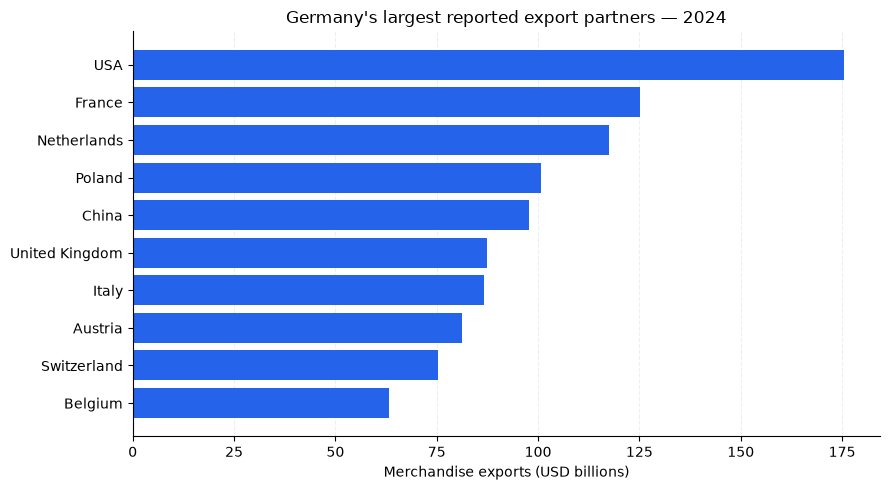

In [8]:
# which trading partners received the largest reported value of Germany's merchandise exports in 2024?
if baseline_df.empty or "partnerCode" not in baseline_df:
    print("Chart skipped: baseline snapshot unavailable.")
else:
    top_partners = (baseline_df.loc[baseline_df["partnerCode"].ne(0)] # exclude World aggregate
                    .nlargest(10, "primaryValue") # select the 10 largest partners
                    .sort_values("primaryValue")) # sort for a better visual
    fig, ax = plt.subplots(figsize=(9, 5)) # create a horizontal bar chart
    ax.barh(top_partners["partnerDesc"], top_partners["primaryValue"] / 1e9, color="#2563eb") # scale billions for visualization
    ax.set(title="Germany's largest reported export partners — 2024",
           xlabel="Merchandise exports (USD billions)")
    ax.grid(axis="x", alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

## 5. Single-Chapter Live Pilot

Before running a twelve-partition batch, test **one** product-level request: 2024 exports of HS chapter 84 across available partners. It is a different query from the `TOTAL` baseline and therefore has its own fingerprint and snapshot.

**Safety:** Leave `RUN_LIVE_PILOT=False` for offline runs. Set it to `True` only when deliberately allowing the client to retrieve (or reuse) this one query. `max_records=2000` is a bound, **not** proof of completeness.

In [ ]:
RUN_LIVE_PILOT = False
# select the single chapter pilot query
pilot_query = next(item["query"] for item in query_specs
                   if (item["year"], item["flow"], item["chapter"]) == ("2024", "X", "84"))

prepared, _ = client._prepare_trade_request(pilot_query)  # Inspect only; no HTTP request.
assert "partnerCode" not in prepared["query_parameters"]
print("Partner filter omitted:", True)
print("Pilot fingerprint:", client.request_fingerprint(pilot_query)[:14])

if RUN_LIVE_PILOT:
    if not client.authenticated:
        raise RuntimeError("A configured UN Comtrade API key is required for live extraction.")
    result = client.download_trade_data(pilot_query)  # May reuse a verified cache entry.
    print("Rows:", result.record_count, "| From cache:", result.from_cache)
    print("Possible truncation:", result.possibly_truncated, "| Warnings:", result.warning_codes)
else:
    pilot_cached = read_cached_snapshot(pilot_query)
    print("Live pilot disabled. Cached pilot available:", pilot_cached is not None)

Partner filter omitted: True
Pilot fingerprint: cf41e8360e7ee7
Rows: 224 | From cache: False
Possible truncation: False | Warnings: ()


## 6. Bounded Batch Execution

The full scope consists of **12 independent partitions** (year × flow × chapter). Keeping requests separate makes them easier to cache, audit, retry, and assess for truncation.

The cell checks which snapshots already exist. **It sends no requests by default**. If enabled, only missing/invalid partitions are retrieved, subject to the client's daily budget, pacing, retry handling, and snapshot safeguards. The maximum planned new requests is capped at 12 **initial calls**; retries can consume additional HTTP attempts within the client's budget.

If a partition comes back at the record limit, do **not** silently treat it as complete. Narrow that partition and reconcile the resulting subpartitions before using the data in a downstream model.

In [ ]:
RUN_LIVE_BATCH = False
MAX_NEW_PARTITIONS = 12
# identify missing responses
missing_specs = [item for item in query_specs if read_cached_snapshot(item["query"]) is None]
print("Planned partitions:", len(query_specs))
print("Usable cached partitions:", len(query_specs) - len(missing_specs))
print("Partitions needing extraction:", len(missing_specs))
# remove the requests that are already present locally
if RUN_LIVE_BATCH:
    if not client.authenticated:
        raise RuntimeError("A configured UN Comtrade API key is required for live extraction.")
    if len(missing_specs) > MAX_NEW_PARTITIONS:
        raise RuntimeError("Batch exceeds the configured partition limit.")
    for item in missing_specs:
        result = client.download_trade_data(item["query"]) # extract data in a sequential batch
        print(item["year"], item["flow"], item["chapter"],
              "| rows:", result.record_count,
              "| possibly truncated:", result.possibly_truncated)
else:
    print("Live batch disabled — no API requests made.")

Planned partitions: 12
Usable cached partitions: 1
Partitions needing extraction: 11
2023 M 84 | rows: 204 | possibly truncated: False
2023 M 85 | rows: 204 | possibly truncated: False
2023 M 87 | rows: 146 | possibly truncated: False
2023 X 84 | rows: 223 | possibly truncated: False
2023 X 85 | rows: 220 | possibly truncated: False
2023 X 87 | rows: 206 | possibly truncated: False
2024 M 84 | rows: 202 | possibly truncated: False
2024 M 85 | rows: 211 | possibly truncated: False
2024 M 87 | rows: 143 | possibly truncated: False
2024 X 85 | rows: 225 | possibly truncated: False
2024 X 87 | rows: 204 | possibly truncated: False


## 7. Build a Snapshot Inventory & Combined DataFrame

For each planned query, load its verified cached snapshot. The inventory distinguishes **available** from **missing** partitions. Each row in the combined DataFrame retains the requested year, flow, chapter, and source filename for traceability.

**Important:** Combining the files here does not establish their completeness or analytical validity. Those checks follow in Section 8. No processed data is written to disk yet.

In [13]:
inventory = [] # inventory stores one summary dictionary per partition
frames = [] # frames stores the actual dataframes containing the records
for item in query_specs:
    cached = read_cached_snapshot(item["query"])
    inventory.append({ # inventory brings together metadata for the combined dataset's completeness
        "year": item["year"], "flow": item["flow"], "chapter": item["chapter"],
        "status": "available" if cached is not None else "missing",
        "rows": len(cached["payload"]["data"]) if cached is not None else 0,
        "possibly_truncated": (bool(cached["metadata"].get("possibly_truncated", True))
                               if cached is not None else None),
        "warning_codes": tuple(cached["metadata"].get("warning_codes") or ())
                         if cached is not None else (),
    })
    if cached is not None:
        part = pd.json_normalize(cached["payload"]["data"]).copy()
        part["requested_year"] = item["year"]
        part["requested_flow"] = item["flow"]
        part["requested_chapter"] = item["chapter"]
        part["source_file"] = cached["path"].name
        frames.append(part)

inventory_df = pd.DataFrame(inventory)
trade_df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame() # combine the dataframes into a single one
print("Available partitions:", int(inventory_df["status"].eq("available").sum()), "/", len(inventory_df))
print("Combined rows:", len(trade_df))
display(inventory_df)

Available partitions: 12 / 12
Combined rows: 2412


,year,flow,chapter,status,rows,possibly_truncated,warning_codes
0,2023,M,84,available,204,False,()
1,2023,M,85,available,204,False,()
2,2023,M,87,available,146,False,()
3,2023,X,84,available,223,False,()
4,2023,X,85,available,220,False,()
5,2023,X,87,available,206,False,()
6,2024,M,84,available,202,False,()
7,2024,M,85,available,211,False,()
8,2024,M,87,available,143,False,()
9,2024,X,84,available,224,False,()


## 8. Validate Grain, Scope & Coverage

Quality checks address distinct questions:

- **Identity:** Is each record unique at the proposed reporter–year–flow–chapter–partner grain?
- **Scope:** Does the response match its requested year, flow, chapter, and reporter?
- **Coverage:** Are all 12 partitions present, with a World record where expected?
- **Validity:** Are trade values numeric and present? Did any query report possible truncation?

A clean result here supports use **within this planned scope**, but cannot prove that the UN Comtrade source contains every theoretically possible bilateral observation. If the data reveal additional varying dimensions (for example, customs or transport breakdowns), reassess the grain rather than deleting duplicates.

In [14]:
# check the partition inventory for possible failures
missing_partitions = int(inventory_df["status"].eq("missing").sum())
flagged_partitions = int(inventory_df["possibly_truncated"].eq(True).sum())
warning_partitions = int(inventory_df["warning_codes"].map(bool).sum())

quality = {"missing_partitions": missing_partitions,
           "possibly_truncated_partitions": flagged_partitions,
           "partitions_with_warnings": warning_partitions}

if trade_df.empty:
    print("No product-level records yet. Enable the pilot or batch explicitly, then rerun Sections 7–9.")
    data_ready = False
else:
    required_cols = {"reporterCode", "period", "flowCode", "cmdCode", "partnerCode", "primaryValue"}
    absent_cols = required_cols - set(trade_df.columns)
    if absent_cols:
        raise ValueError(f"Expected source columns missing: {sorted(absent_cols)}")
    # standardize data types
    trade_df["period"] = trade_df["period"].astype(str)
    trade_df["flowCode"] = trade_df["flowCode"].astype(str)
    trade_df["cmdCode"] = trade_df["cmdCode"].astype(str)
    trade_df["partnerCode"] = pd.to_numeric(trade_df["partnerCode"], errors="coerce")
    trade_df["primaryValue"] = pd.to_numeric(trade_df["primaryValue"], errors="coerce")
    # check for business-grain uniqueness
    grain = ["reporterCode", "period", "flowCode", "cmdCode", "partnerCode"]
    quality["duplicate_grain_rows"] = int(trade_df.duplicated(grain).sum())
    quality["missing_trade_values"] = int(trade_df["primaryValue"].isna().sum())
    quality["invalid_partner_codes"] = int(trade_df["partnerCode"].isna().sum())
    # validate the scope is in place, nothing out of the goal is present
    quality["out_of_scope_rows"] = int((
        trade_df["period"].ne(trade_df["requested_year"])
        | trade_df["flowCode"].ne(trade_df["requested_flow"])
        | trade_df["cmdCode"].ne(trade_df["requested_chapter"])
        | pd.to_numeric(trade_df["reporterCode"], errors="coerce").ne(276)
    ).sum())
    # make sure we have 1 World observation per partition
    world_counts = (trade_df.assign(is_world=trade_df["partnerCode"].eq(0))
                    .groupby(["requested_year", "requested_flow", "requested_chapter"])["is_world"]
                    .sum())
    quality["partitions_without_one_world_row"] = int(world_counts.ne(1).sum())
    data_ready = (all(value == 0 for value in quality.values())
                  and len(world_counts) == len(query_specs))
    display(pd.DataFrame([quality]))
    print("All partitions passed defined checks:", data_ready)

,missing_partitions,possibly_truncated_partitions,partitions_with_warnings,duplicate_grain_rows,missing_trade_values,invalid_partner_codes,out_of_scope_rows,partitions_without_one_world_row
0,0,0,0,0,0,0,0,0


All partitions passed defined checks: True


## 9. Analytical Preview — World-Level HS Chapters

Only if **all planned partitions pass** the Section 8 checks, select `partnerCode=0` and compare each chapter by year and trade flow. This avoids mixing World with individual-partner observations. The resulting table is a **preview**, not a persistent analytics mart.

No cross-country or cross-HS-level sums are used to claim completeness. Differences between years should be interpreted carefully because source coverage and HS editions can change.

In [17]:
if not data_ready: # validation checks must pass before analytical work begins
    chapter_world = pd.DataFrame()
    print("Analytical preview skipped: extraction scope is missing or has unresolved quality flags.")
else:
    chapter_world = trade_df.loc[trade_df["partnerCode"].eq(0)].copy() # copy World observaiton, don't modify original
    chapter_summary = (chapter_world.pivot( # bring together exports and imports into a pivot table
        index=["period", "cmdCode"], columns="flowCode", values="primaryValue")
        .rename(columns={"M": "imports_usd", "X": "exports_usd"}).reset_index())
    chapter_summary.columns.name = None
    chapter_summary["trade_balance_usd"] = chapter_summary["exports_usd"] - chapter_summary["imports_usd"] # create trade balance
    print("World-level chapter summaries (USD billions):")
    shown = chapter_summary.copy()
    for col in ("imports_usd", "exports_usd", "trade_balance_usd"):
        shown[col] = shown[col] / 1e9
    display(shown.round(2).sort_values(["cmdCode", "period"]).reset_index(drop=True)
        .rename(columns={"period": "Year", "cmdCode": "HS Chapter", "imports_usd": "Imports (USD bn)", "exports_usd": "Exports (USD bn)", "trade_balance_usd": "Trade Balance (USD bn)"}))

World-level chapter summaries (USD billions):


,Year,HS Chapter,Imports (USD bn),Exports (USD bn),Trade Balance (USD bn)
0,2023,84,179.23,277.47,98.24
1,2024,84,174.71,271.79,97.08
2,2023,85,225.96,192.97,-32.99
3,2024,85,210.23,181.89,-28.34
4,2023,87,160.69,297.61,136.92
5,2024,87,148.61,285.78,137.17


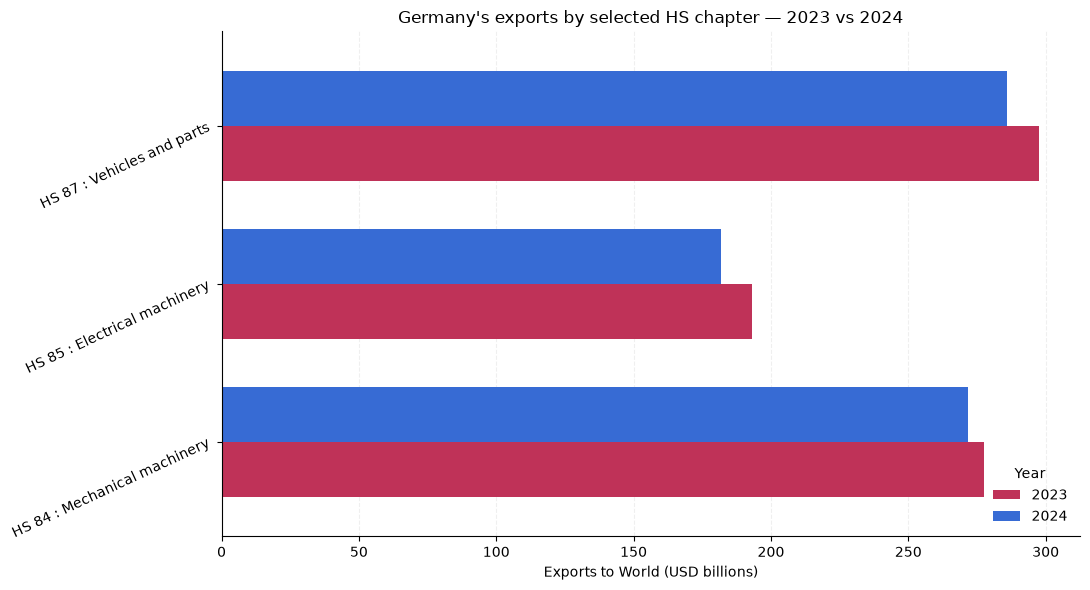

In [26]:
if chapter_world.empty:
    print("Chart skipped until all 12 partitions pass quality checks.")
else:
    export_world = chapter_world.loc[chapter_world["flowCode"].eq("X")].copy()
    chart_data = (export_world.pivot(index="cmdCode", columns="period", values="primaryValue") / 1e9)
    chart_data.index = [f"HS {code} : {CHAPTERS.get(code, code)}" for code in chart_data.index]
    ax = chart_data.plot.barh(figsize=(11, 6), width=0.7, color=["#bf3258", "#376bd4"])
    ax.set(title="Germany's exports by selected HS chapter — 2023 vs 2024",
           xlabel="Exports to World (USD billions)", ylabel="")
    ax.grid(axis="x", alpha=0.2, linestyle="--")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(title="Year", frameon=False)
    plt.yticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## 10. Conclusion — Extraction & Data Readiness

This notebook implemented and validated a bounded extraction workflow for Germany's merchandise trade across three HS chapters (84, 85, 87), two years (2023–2024), and both import and export flows.

### Key Findings

- **Extraction:** All 12 planned partitions were retrieved successfully, producing **2,412 observations** across available trading partners.
- **Reproducibility:** Independent raw snapshots were stored and subsequently loaded from cache with request fingerprints, metadata, and checksum verification.
- **Data quality:** All defined checks passed, with no missing partitions, duplicate business keys, invalid partner codes, missing trade values, out-of-scope observations, or reported truncation.
- **Analytical readiness:** The validated data supported chapter-level import, export, and trade balance comparisons across 2023 and 2024.
- **Aggregation:** World totals were kept separate from individual partner observations to avoid double-counting.

### Limitations

These results establish internal consistency for the selected extraction scope, not exhaustive partner coverage or independent verification of source accuracy. HS classification comparability and broader extraction completeness require additional assessment before expanding the dataset.

### Final Assessment

**The bounded extraction workflow is operational and passes its defined data-quality checks.** The resulting raw snapshots provide a traceable foundation for relational staging and analytical modeling.